# Frozen graph score and representation diagnosis
Read the previous nine runs' selected and final checkpoints. Diagnose score shifts, calibration, raw degree distributions, representation RMS, classifier-weighted contributions and cross-coverage ranking. No model training, calibration fitting, threshold selection or test scoring. Existing inputs and checkpoints remain immutable.
Train scores are in-sample diagnostics. Validation has 144 users, including only seven graph-covered bots. Each seed is analyzed separately; observations across seeds are not independent users.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/graph_diagnosis_v1.json').exists())
sys.path.insert(0, str(ROOT))
from src.graph_diagnosis import run, verify
output_dir, tables = run(ROOT)
print('OUTPUT_VERSION:', output_dir)
verification = verify(ROOT, output_dir)
print(verification)

C:\Users\p.vazifeh\Desktop\University\Project\Bot Detection Implementation\env\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Diagnosed temporal_anchor_seed42, best_unweighted_validation_loss


Diagnosed temporal_anchor_seed42, last


Diagnosed degree_mlp_seed42, best_unweighted_validation_loss


Diagnosed degree_mlp_seed42, last


...

Diagnosed degree_mlp_seed44, last


Diagnosed gcn_seed44, best_unweighted_validation_loss


Diagnosed gcn_seed44, last


OUTPUT_VERSION: C:\Users\p.vazifeh\Desktop\University\Project\Bot Detection Implementation\results\versions\graph_diagnosis_v1\20260922T050323622224Z_abbeded5


{'artifacts_verified': 60, 'checkpoints_diagnosed': 18, 'keyed_files_verified': 36, 'test_inputs_parsed': 0, 'training_performed': False, 'max_logit_reconstruction_error': 1.9073486328125e-06}


## Scores and reliability
Keep the 0.5 threshold fixed. Reliability uses ten fixed-width bins, including empty-bin counts. BCE/Brier and binned ECE are descriptive; no calibrator is fitted. Decompose overall ROC-AUC into bot/human pairs within and across graph availability groups; weighted pair contributions must sum to overall AUC.

,arm,seed,policy,split,cohort,n,bots,threshold,bot_precision,bot_recall,...,fn,tp,predicted_bots,roc_auc,average_precision,brier,unweighted_log_loss,ece_10_bins,saturated_zero_count,saturated_one_count
3,degree_mlp,42,best_unweighted_validation_loss,validation,all,144,28,0.5,0.271186,0.571429,...,12,16,59,0.693350,0.332121,0.225997,0.642942,0.278839,0,0
4,degree_mlp,42,best_unweighted_validation_loss,validation,graph_available,42,7,0.5,1.000000,0.142857,...,6,1,1,0.897959,0.759805,0.161874,0.510196,0.231626,0,0
5,degree_mlp,42,best_unweighted_validation_loss,validation,graph_unavailable,102,21,0.5,0.258621,0.714286,...,6,15,58,0.659612,0.342619,0.252401,0.697602,0.307838,0,0
15,degree_mlp,43,best_unweighted_validation_loss,validation,all,144,28,0.5,0.270833,0.464286,...,15,13,48,0.633929,0.288361,0.205652,0.597158,0.220140,0,0
16,degree_mlp,43,best_unweighted_validation_loss,validation,graph_available,42,7,0.5,0.000000,0.000000,...,7,0,0,0.955102,0.811998,0.131502,0.432526,0.144607,0,0
17,degree_mlp,43,best_unweighted_validation_loss,validation,graph_unavailable,102,21,0.5,0.270833,0.619048,...,8,13,48,0.637860,0.306620,0.236185,0.664948,0.278343,0,0
27,degree_mlp,44,best_unweighted_validation_loss,validation,all,144,28,0.5,0.361702,0.607143,...,11,17,47,0.737993,0.497377,0.193227,0.574476,0.201444,0,0
28,degree_mlp,44,best_unweighted_validation_loss,validation,graph_available,42,7,0.5,0.571429,0.571429,...,3,4,7,0.857143,0.699431,0.133325,0.436016,0.206375,0,0
29,degree_mlp,44,best_unweighted_validation_loss,validation,graph_unavailable,102,21,0.5,0.325000,0.619048,...,8,13,40,0.734862,0.534090,0.217893,0.631488,0.213813,0,0
39,gcn,42,best_unweighted_validation_loss,validation,all,144,28,0.5,0.241379,0.500000,...,14,14,58,0.627463,0.276534,0.210662,0.605296,0.225864,0,0


,arm,seed,policy,split,bot_has_graph,human_has_graph,pairs,pair_weight,pair_auc,weighted_auc_contribution
4,degree_mlp,42,best_unweighted_validation_loss,validation,0,0,1701,0.523707,0.659612,0.345443
5,degree_mlp,42,best_unweighted_validation_loss,validation,0,1,735,0.226293,0.956463,0.216441
6,degree_mlp,42,best_unweighted_validation_loss,validation,1,0,567,0.174569,0.365079,0.063732
7,degree_mlp,42,best_unweighted_validation_loss,validation,1,1,245,0.075431,0.897959,0.067734
20,degree_mlp,43,best_unweighted_validation_loss,validation,0,0,1701,0.523707,0.637860,0.334052
21,degree_mlp,43,best_unweighted_validation_loss,validation,0,1,735,0.226293,1.000000,0.226293
22,degree_mlp,43,best_unweighted_validation_loss,validation,1,0,567,0.174569,0.008818,0.001539
23,degree_mlp,43,best_unweighted_validation_loss,validation,1,1,245,0.075431,0.955102,0.072044
36,degree_mlp,44,best_unweighted_validation_loss,validation,0,0,1701,0.523707,0.734862,0.384852
37,degree_mlp,44,best_unweighted_validation_loss,validation,0,1,735,0.226293,0.741497,0.167796


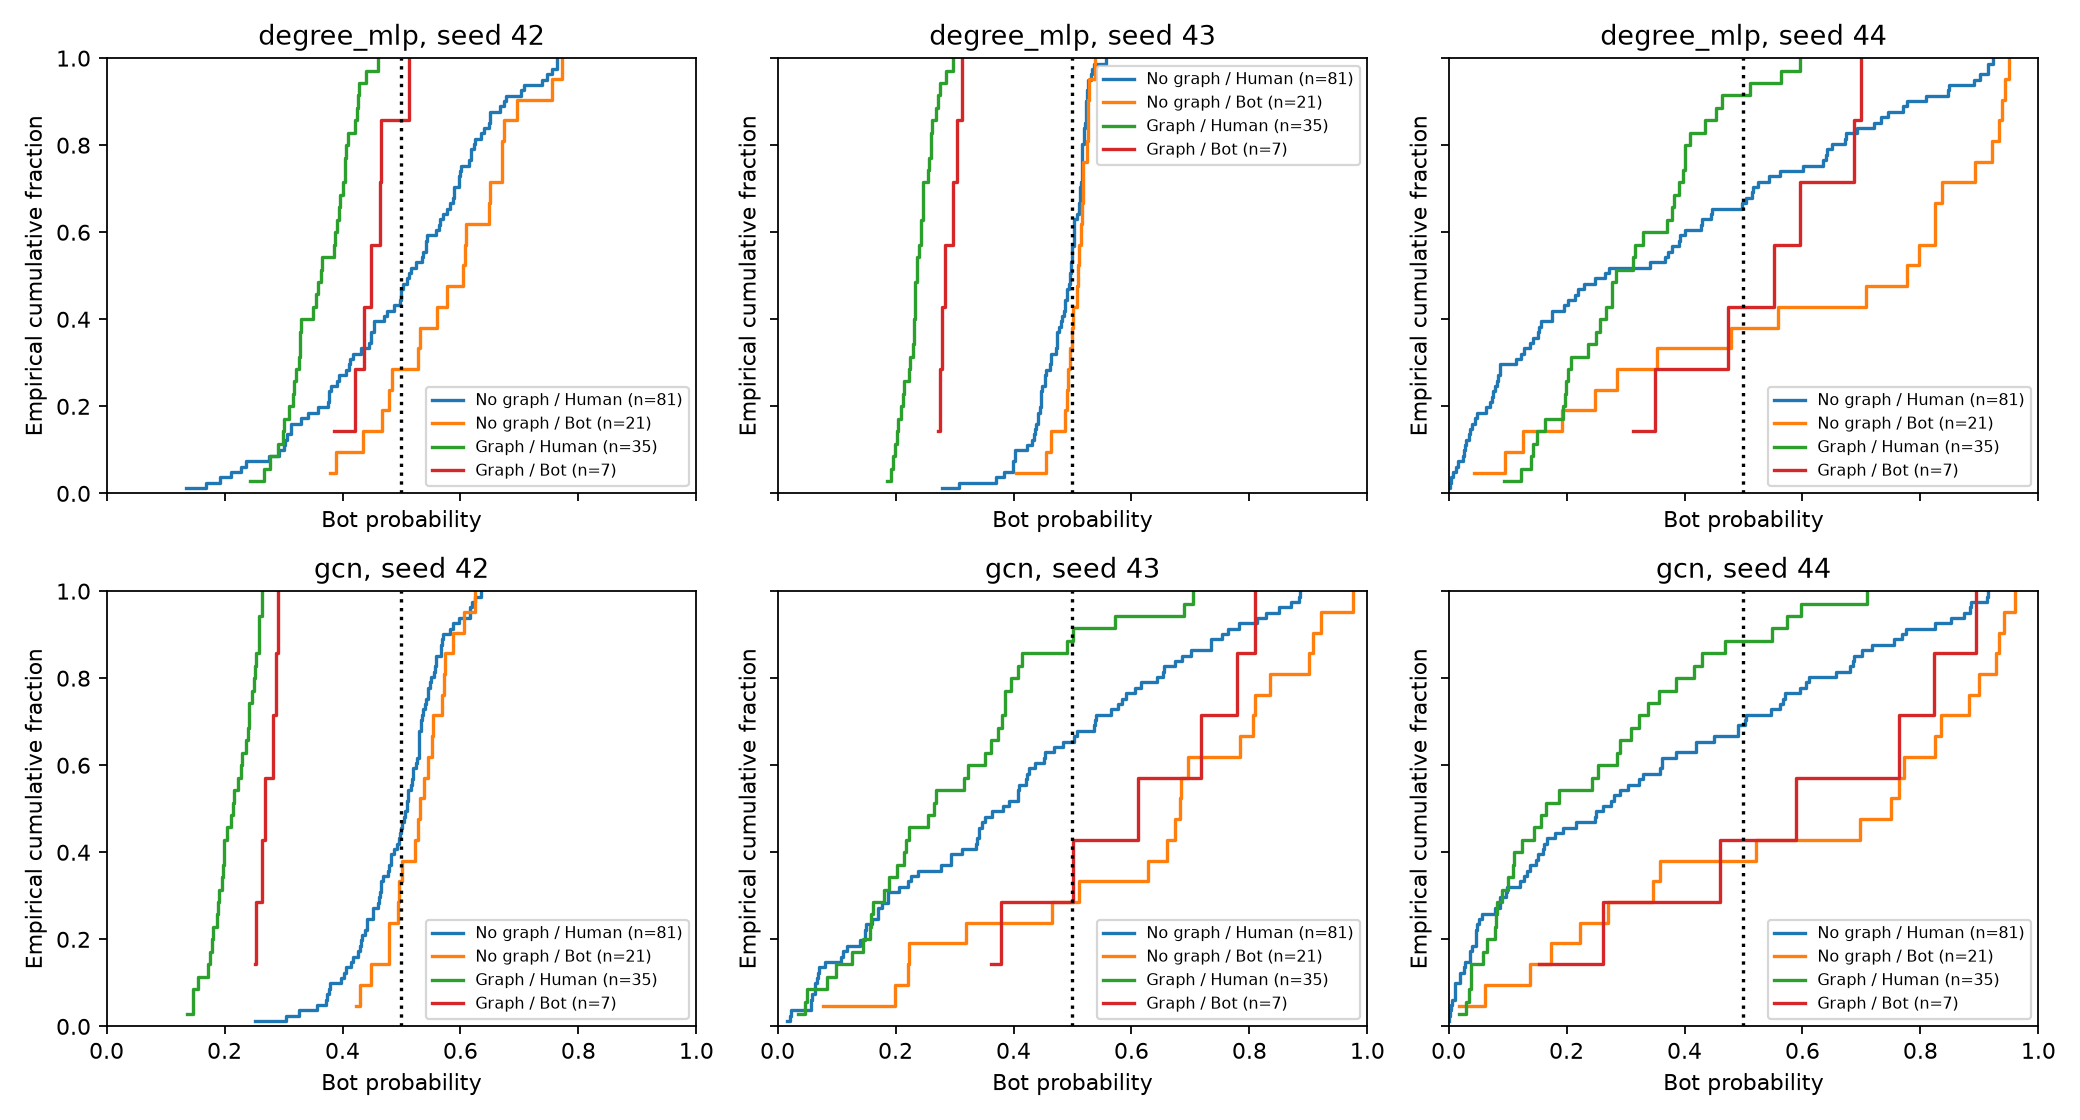

In [2]:
import pandas as pd
from IPython.display import Image, display
def selected_validation(df):
    return df[df.split.eq('validation') & df.policy.eq('best_unweighted_validation_loss')]
display(selected_validation(tables['score_metrics']))
display(selected_validation(tables['auc_pair_decomposition']))
display(Image(filename=str(output_dir / 'figures/score_ecdf.png')))

## Representation and classifier diagnostics
Compare RMS as well as L2 because branches have different widths. Weighted RMS measures each branch's contribution before the first fusion ReLU. Signed logit terms exactly reconstruct the observed logit conditional on that ReLU mask; they are not causal attributions.
Zeroing the graph representation recomputes the classifier's nonlinear activations. This is an inference perturbation, potentially out of distribution for graph-covered users, not a retrained ablation or a model candidate. Missing-graph users must have exactly zero perturbation effect.

,split,population,n,degree_min,degree_q05,degree_q25,degree_median,degree_q75,degree_q95,degree_max,degree_mean
0,train,all_observed_nodes,42954,1.0,1.00,1.00,1.0,1.0,3.0,389.0,2.836709
1,train,non_gold_support_nodes,42381,1.0,1.00,1.00,1.0,1.0,3.0,45.0,1.386305
2,train,graph_available_canonical_users,193,87.0,230.40,309.00,326.0,340.0,365.0,389.0,318.740933
3,validation,all_observed_nodes,11436,1.0,1.00,1.00,1.0,1.0,2.0,360.0,2.274572
4,validation,non_gold_support_nodes,11352,1.0,1.00,1.00,1.0,1.0,2.0,17.0,1.136276
5,validation,graph_available_canonical_users,42,252.0,270.25,298.25,311.0,323.0,348.8,360.0,310.595238


,arm,seed,policy,split,cohort,label,n,original_minus_zero_graph_logit_min,original_minus_zero_graph_logit_q05,original_minus_zero_graph_logit_q25,...,original_minus_zero_graph_probability_q25,original_minus_zero_graph_probability_median,original_minus_zero_graph_probability_q75,original_minus_zero_graph_probability_q95,original_minus_zero_graph_probability_max,original_minus_zero_graph_probability_mean,flipped_to_bot,flipped_to_human,original_errors,zero_graph_errors
6,degree_mlp,42,best_unweighted_validation_loss,validation,all,0,116,-0.782819,-0.603258,0.000000,...,0.000000,0.000000,0.000000,0.011086,0.070535,-0.018956,12,0,43,55
7,degree_mlp,42,best_unweighted_validation_loss,validation,all,1,28,-1.288601,-0.926046,-0.113795,...,-0.027928,0.000000,0.000000,0.000000,0.000000,-0.046855,5,0,12,7
8,degree_mlp,42,best_unweighted_validation_loss,validation,graph_available,0,35,-0.782819,-0.742171,-0.519925,...,-0.128780,-0.057051,-0.003374,0.054256,0.070535,-0.062827,12,0,0,12
9,degree_mlp,42,best_unweighted_validation_loss,validation,graph_available,1,7,-1.288601,-1.195481,-0.903694,...,-0.216969,-0.174759,-0.155880,-0.123567,-0.111713,-0.187419,5,0,6,1
10,degree_mlp,42,best_unweighted_validation_loss,validation,graph_unavailable,0,81,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0,0,43,43
11,degree_mlp,42,best_unweighted_validation_loss,validation,graph_unavailable,1,21,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0,0,6,6
30,degree_mlp,43,best_unweighted_validation_loss,validation,all,0,116,-1.330644,-1.128081,-0.912422,...,-0.201479,0.000000,0.000000,0.000000,0.000000,-0.068555,8,0,35,43
31,degree_mlp,43,best_unweighted_validation_loss,validation,all,1,28,-1.132617,-1.055825,-0.214977,...,-0.050991,0.000000,0.000000,0.000000,0.000000,-0.058212,7,0,15,8
32,degree_mlp,43,best_unweighted_validation_loss,validation,graph_available,0,35,-1.330644,-1.213814,-1.087429,...,-0.246409,-0.231498,-0.209228,-0.177320,-0.114769,-0.227212,8,0,0,8
33,degree_mlp,43,best_unweighted_validation_loss,validation,graph_available,1,7,-1.132617,-1.118935,-1.042459,...,-0.244334,-0.229807,-0.221270,-0.209000,-0.203964,-0.232850,7,0,7,0


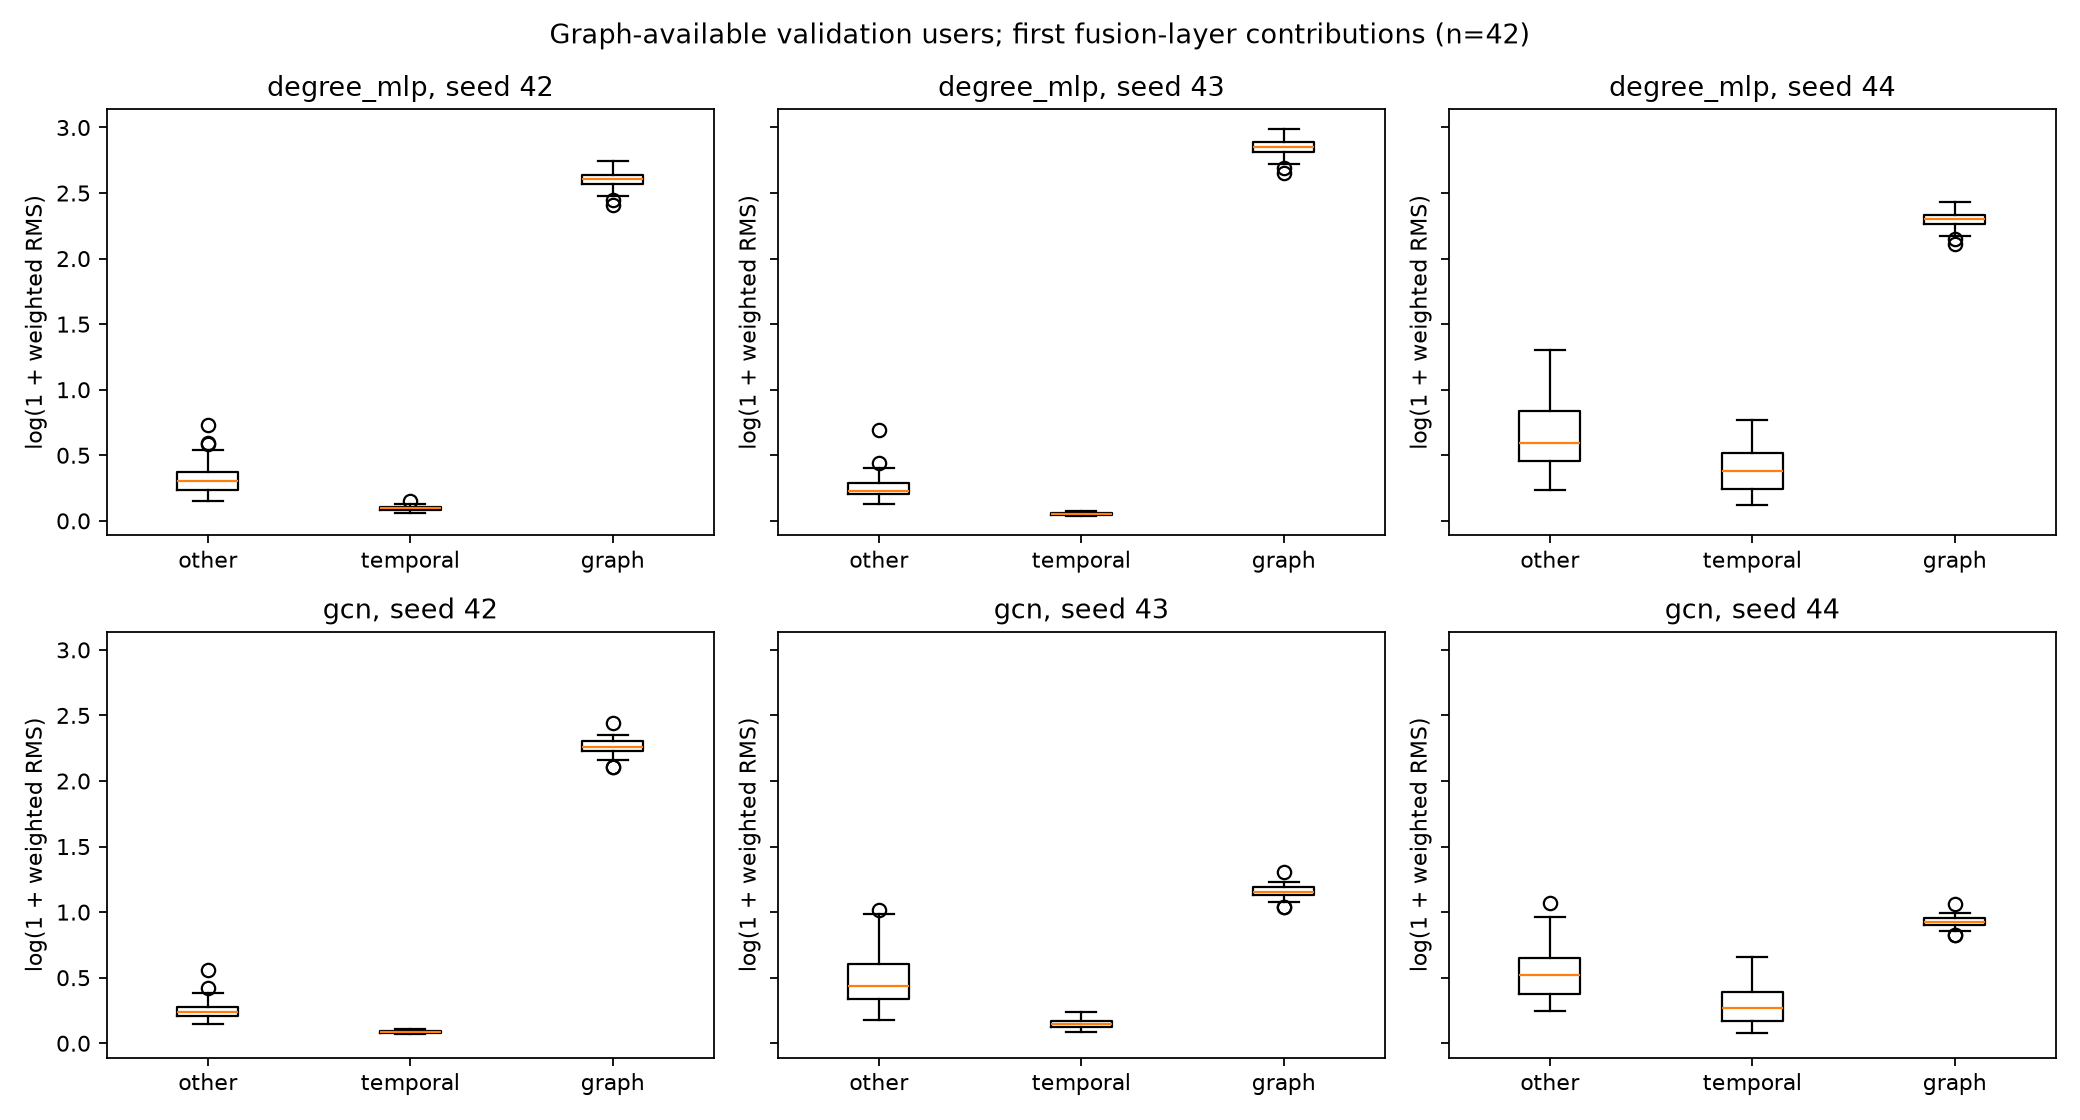

In [3]:
display(pd.read_csv(output_dir / 'raw_degree_distributions.csv'))
display(selected_validation(tables['inference_perturbation_summary']))
display(Image(filename=str(output_dir / 'figures/weighted_representation_scale.png')))

## Interpretation
Consult reports/GRAPH_SCORE_REPRESENTATION_DIAGNOSIS.md for findings and the next controlled proposal. No architecture, checkpoint, threshold or preprocessing policy is promoted by this notebook. Source and output hashes, keyed diagnostics, reconstruction errors and protocol details accompany every versioned run.